In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm

In [2]:
# Read the MySQL export (any NULL values are treated as missing) and convert Date to a date type
df = pd.read_csv("../data/processed/master_monthly_features.csv", sep=";", na_values=["NULL"])

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

In [3]:
print("Shape of imported data:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values by column:")
print(df.isna().sum())

print("\nFirst 5 rows:")
print(df.head())

print("\nLast five rows:")
print(df.tail())

Shape of imported data: (233, 24)

Column names:
['Date', 'CPI', 'GasPrices', 'UnemploymentRate', 'DisposableIncome', 'ConsumerSpending', 'MortgageRates', 'FedFundsRate', 'ConsumerSentiment', 'HourlyWages', 'SavingsRate', 'Inflation', 'WageGrowth_YoY', 'FedFundsRate_Lag3', 'ConsumerSentiment_Lag1', 'RealWageGrowth', 'ConsumerSpending_YoY', 'DisposableIncome_YoY', 'GasPrices_YoY', 'UnemploymentRate_MoM', 'ConsumerSentiment_MoM', 'RealFedFundsRate', 'RealMortgageRate', 'RealHourlyWages']

Data types:
Date                      datetime64[us]
CPI                              float64
GasPrices                        float64
UnemploymentRate                 float64
DisposableIncome                   int64
ConsumerSpending                 float64
MortgageRates                    float64
FedFundsRate                     float64
ConsumerSentiment                float64
HourlyWages                      float64
SavingsRate                      float64
Inflation                        float64
Wage

# Create dataset for modeling

In [4]:
# Remove rows with expected missing values created by lagged features
calc_cols = ["Inflation", "WageGrowth_YoY", "RealWageGrowth", "ConsumerSpending_YoY",
             "DisposableIncome_YoY", "GasPrices_YoY", "RealFedFundsRate", "RealMortgageRate"]
df.loc[df["Date"] < "2008-01-01", calc_cols] = None

model_data = df.dropna().copy()
model_data = model_data.sort_values("Date").reset_index(drop=True)

print("\nShape of modeling data set after dropping all expected null values:",
      model_data.shape)
print("\nNew Date range for modeling data set:",
      model_data["Date"].min(), "to", model_data["Date"].max())



Shape of modeling data set after dropping all expected null values: (221, 24)

New Date range for modeling data set: 2008-01-01 00:00:00 to 2026-05-01 00:00:00


# Augmented Dickey-Fuller (ADF) tests

In [5]:
def run_adf(series, name):
    result = adfuller(series.dropna(), result_object=False)
    stationary = "Stationary" if result[1] < 0.05 else "Non-Stationary"
    print(f"{name:25s} ADF stat={result[0]:8.3f} p-value={result[1]:.4f} -> {stationary}")

print("--- Raw level variables ---")
for col in ["CPI", "DisposableIncome", "ConsumerSpending", "HourlyWages",
            "UnemploymentRate", "MortgageRates", "FedFundsRate",
            "ConsumerSentiment", "GasPrices", "SavingsRate"]:
    run_adf(model_data[col], col)

print("\n--- Engineered growth-rate / real variables ---")
for col in ["Inflation", "WageGrowth_YoY", "RealWageGrowth",
            "ConsumerSpending_YoY", "DisposableIncome_YoY", "GasPrices_YoY",
            "UnemploymentRate_MoM", "ConsumerSentiment_MoM",
            "RealFedFundsRate", "RealMortgageRate"]:
    run_adf(model_data[col], col)

--- Raw level variables ---
CPI                       ADF stat=   2.681 p-value=0.9991 -> Non-Stationary
DisposableIncome          ADF stat=  -0.437 p-value=0.9037 -> Non-Stationary
ConsumerSpending          ADF stat=   1.001 p-value=0.9943 -> Non-Stationary
HourlyWages               ADF stat=   5.594 p-value=1.0000 -> Non-Stationary
UnemploymentRate          ADF stat=  -2.530 p-value=0.1084 -> Non-Stationary
MortgageRates             ADF stat=  -1.249 p-value=0.6520 -> Non-Stationary
FedFundsRate              ADF stat=  -1.855 p-value=0.3534 -> Non-Stationary
ConsumerSentiment         ADF stat=  -0.801 p-value=0.8188 -> Non-Stationary
GasPrices                 ADF stat=  -2.931 p-value=0.0419 -> Stationary
SavingsRate               ADF stat=  -2.857 p-value=0.0506 -> Non-Stationary

--- Engineered growth-rate / real variables ---
Inflation                 ADF stat=  -2.169 p-value=0.2179 -> Non-Stationary
WageGrowth_YoY            ADF stat=  -1.080 p-value=0.7229 -> Non-Stationary
Rea

*   Raw levels (CPI, DisposableIncome, ConsumerSpending, HourlyWages, UnemploymentRate, MortgageRates, FedFundsRate, ConsumerSentiment) are all non-stationary and will be omitted from the direct model.
*   SavingsRate (p=0.051), RealWageGrowth/target (p=0.056), and GasPrices_YoY (p=0.052) are all borderline non-stationary, just outside the 0.05 cutoff. No keep/drop decision is made for these three at this stage; they are carried forward and evaluated against the correlation and robustness evidence in the following sections.
*   ConsumerSpending_YoY, DisposableIncome_YoY, UnemploymentRate_MoM, ConsumerSentiment_MoM, RealFedFundsRate, and RealMortgageRate all pass cleanly as stationary.
*   Inflation and WageGrowth_YoY remain non-stationary individually, despite RealWageGrowth (their difference) being only marginally non-stationary.

Current Predictor Set:

*   SavingsRate, ConsumerSpending_YoY, DisposableIncome_YoY, GasPrices_YoY, UnemploymentRate_MoM, ConsumerSentiment_MoM, RealFedFundsRate, RealMortgageRate


In [6]:
# Define target as well as predictors based on stationarity results
TARGET = "RealWageGrowth"

predictors = ["SavingsRate",
              "ConsumerSpending_YoY",
              "DisposableIncome_YoY",
              "GasPrices_YoY",
              "UnemploymentRate_MoM",
              "ConsumerSentiment_MoM",
              "RealFedFundsRate",
              "RealMortgageRate"]

# EDA: Time series

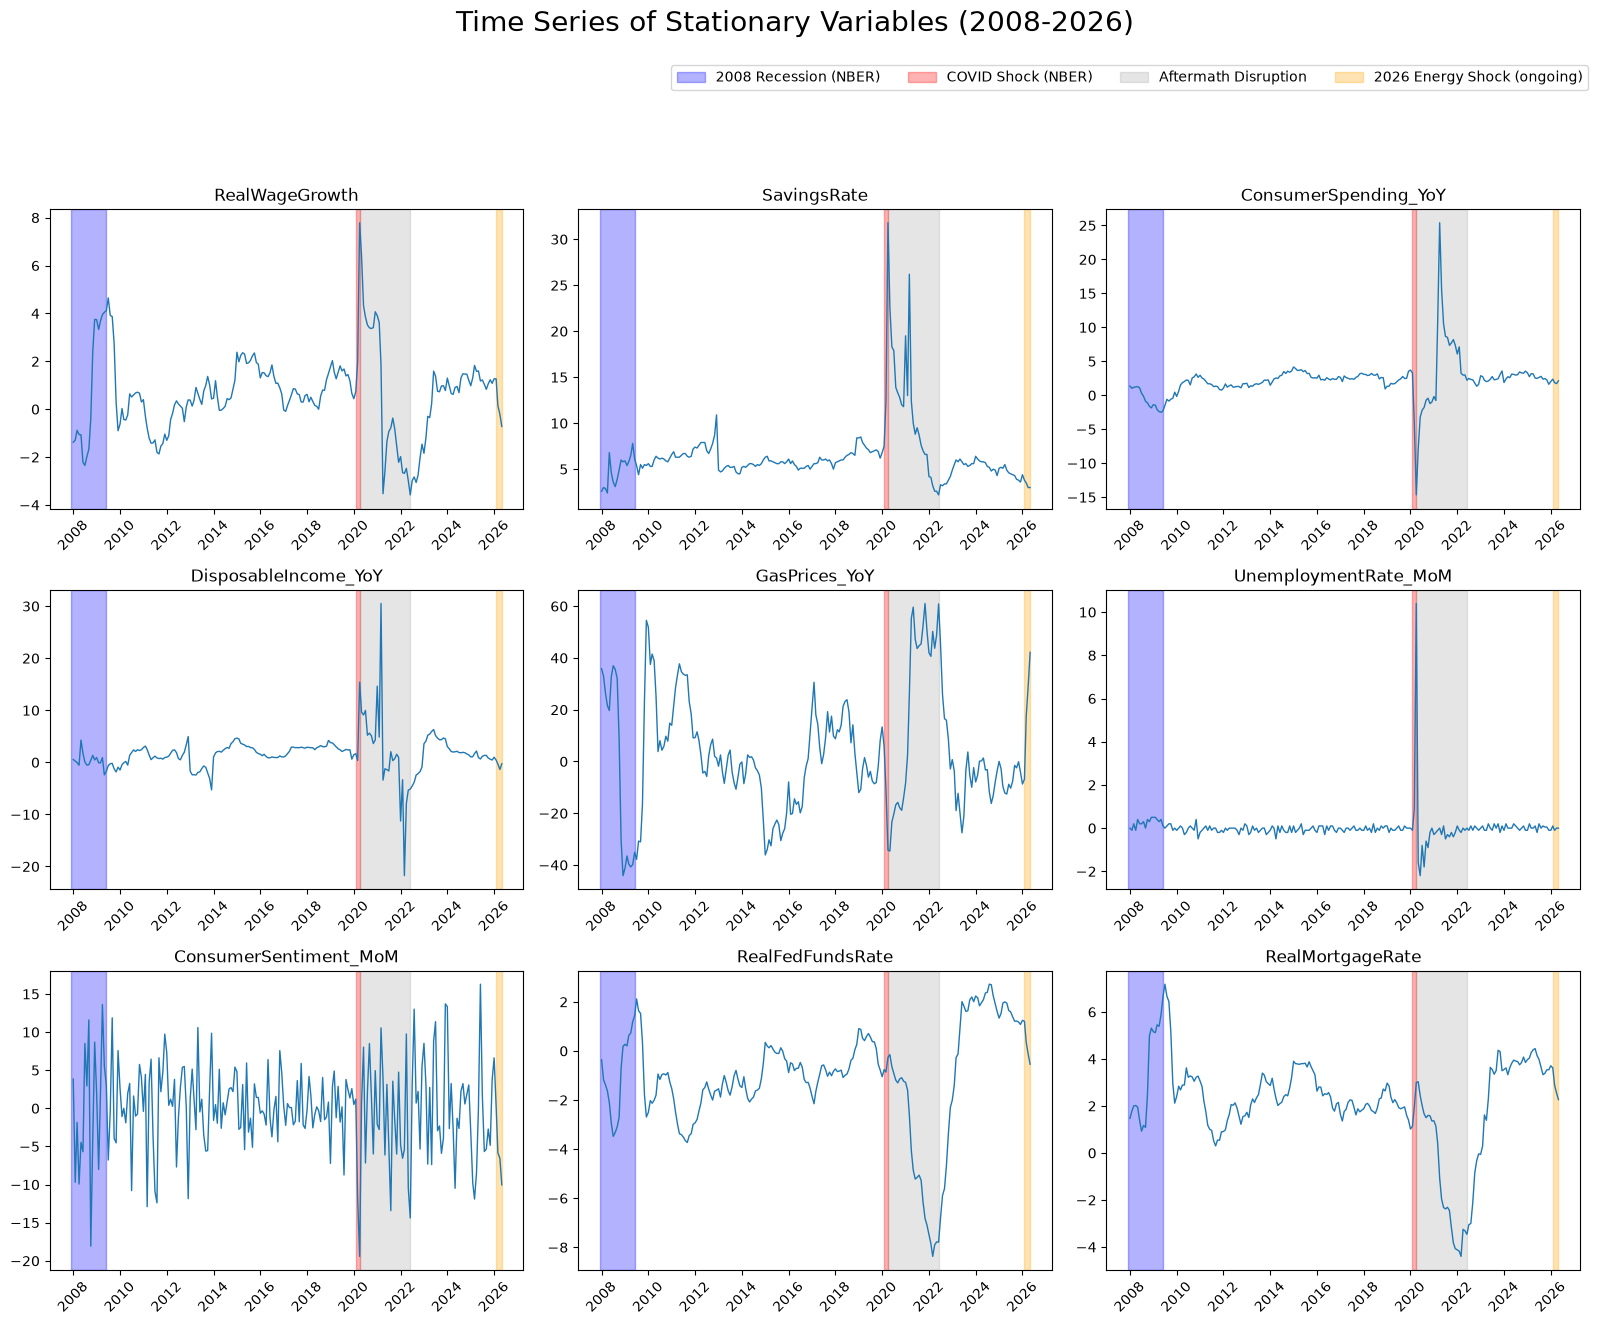

In [7]:
# Create time series plots of stationary variables with COVID highlight

# National Bureau of Economic Research (NBER) dated recessions
recession_2008_start = pd.to_datetime("2007-12-01")
recession_2008_end = pd.to_datetime("2009-06-01")

covid_shock_start = pd.to_datetime("2020-02-01")
covid_shock_end = pd.to_datetime("2020-04-01")

# Extended aftermath period (supply chains, inflation, stimulus)
covid_aftermath_start = pd.to_datetime("2020-04-01")
covid_aftermath_end = pd.to_datetime("2022-06-01")

# Ongoing energy shock due to Middle East conflict
energy_shock_start = pd.to_datetime("2026-02-01")
energy_shock_end = model_data["Date"].max()

ts_vars = [TARGET] + predictors

fig, axes = plt.subplots(3, 3, figsize=(16,12))
axes = axes.flatten()

for i, col in enumerate(ts_vars):
    axes[i].plot(model_data["Date"], model_data[col], linewidth=1)
    axes[i].axvspan(recession_2008_start, recession_2008_end, color="blue", alpha=0.3, label="2008 Recession (NBER)")
    axes[i].axvspan(covid_shock_start, covid_shock_end, color="red", alpha=0.3, label="COVID Shock (NBER)")
    axes[i].axvspan(covid_aftermath_start, covid_aftermath_end, color="gray", alpha=0.2, label="Aftermath Disruption")
    axes[i].axvspan(energy_shock_start, energy_shock_end, color="orange", alpha=0.3, label="2026 Energy Shock (ongoing)")
    axes[i].set_title(col)
    axes[i].tick_params(axis="x", rotation=45)

for j in range(len(ts_vars), len(axes)):
    axes[j].set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right", bbox_to_anchor=(1.0,1.06), ncol=4)

fig.suptitle("Time Series of Stationary Variables (2008-2026)", x=0.5, y=1.1, fontsize=20, ha="center")
plt.tight_layout()
plt.show()

# EDA: Correlation matrix

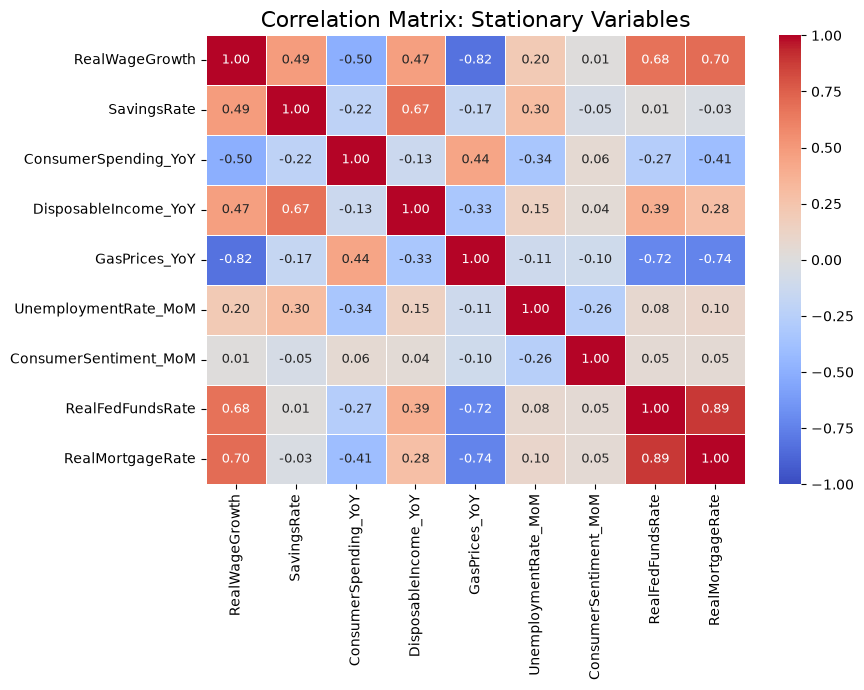

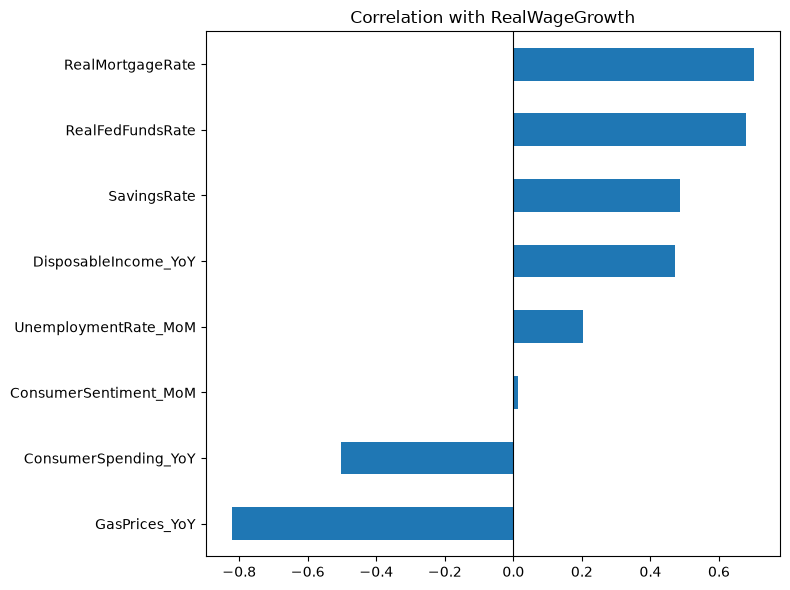

RealMortgageRate         0.701964
RealFedFundsRate         0.677731
SavingsRate              0.485345
DisposableIncome_YoY     0.471842
UnemploymentRate_MoM     0.204669
ConsumerSentiment_MoM    0.012180
ConsumerSpending_YoY    -0.503382
GasPrices_YoY           -0.821424
Name: RealWageGrowth, dtype: float64


In [8]:
corr_vars = [TARGET] + predictors

# Correlation matrix (heatmap)
corr_matrix = model_data[corr_vars].corr()

plt.figure(figsize=(9,7))
ax = sns.heatmap(corr_matrix,
                 cmap="coolwarm",
                 vmin=-1,
                 vmax=1,
                 annot=True,
                 fmt=".2f",
                 linewidth=0.5,
                 annot_kws={"fontsize": 9})

ax.set_title("Correlation Matrix: Stationary Variables", fontsize=16)
plt.tight_layout()
plt.show()

# Rank predictors by correlation strength with target variable
corr_with_target = corr_matrix[TARGET].drop(TARGET).sort_values()

plt.figure(figsize=(8,6))
corr_with_target.plot.barh()
plt.title(f"Correlation with {TARGET}")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

print(corr_with_target.sort_values(ascending=False))

# Robustness Check

In [9]:
# Define crisis period for exclusion
recession_mask = (model_data["Date"] >= recession_2008_start) & (model_data["Date"] <= recession_2008_end)
covid_mask = (model_data["Date"] >= covid_shock_start) & (model_data["Date"] <= covid_aftermath_end)
energy_mask = (model_data["Date"] >= energy_shock_start) & (model_data["Date"] <= energy_shock_end)

full_sample = model_data
recession_exc1 = model_data[~recession_mask]
covid_exc1 = model_data[~covid_mask]
energy_exc1 = model_data[~energy_mask]
all_exc1 = model_data[~(recession_mask | covid_mask | energy_mask)]

print("Full Sample:", len(full_sample))
print("Excluding 2008 Recession:", len(recession_exc1))
print("Excluding COVID:", len(covid_exc1))
print("Excluding Energy Shock:", len(energy_exc1))
print("Excluding All Crises:", len(all_exc1))

comparison = pd.DataFrame({
    "Full Sample": full_sample[corr_vars].corr()[TARGET].drop(TARGET),
    "Excluding 2008 Recession": recession_exc1[corr_vars].corr()[TARGET].drop(TARGET),
    "Excluding COVID": covid_exc1[corr_vars].corr()[TARGET].drop(TARGET),
    "Excluding Energy Shock": energy_exc1[corr_vars].corr()[TARGET].drop(TARGET),
    "Excluding All Crises": all_exc1[corr_vars].corr()[TARGET].drop(TARGET)
})

print(comparison)

Full Sample: 221
Excluding 2008 Recession: 203
Excluding COVID: 192
Excluding Energy Shock: 217
Excluding All Crises: 170
                       Full Sample  Excluding 2008 Recession  Excluding COVID  \
SavingsRate               0.485345                  0.503405         0.216693   
ConsumerSpending_YoY     -0.503382                 -0.516783        -0.140287   
DisposableIncome_YoY      0.471842                  0.543986         0.181988   
GasPrices_YoY            -0.821424                 -0.784812        -0.826372   
UnemploymentRate_MoM      0.204669                  0.205017         0.230898   
ConsumerSentiment_MoM     0.012180                 -0.037701        -0.001654   
RealFedFundsRate          0.677731                  0.676083         0.745326   
RealMortgageRate          0.701964                  0.677090         0.857553   

                       Excluding Energy Shock  Excluding All Crises  
SavingsRate                          0.484542              0.052324  
Consumer

*   RealFedFundsRate and RealMortgageRate are the most robust predictors. Both weaken slightly when the 2008 Recession is excluded (0.678 to 0.676 and 0.702 to 0.677) but strengthen under every other exclusion, most notably when COVID is excluded alone and again under full-crisis exclusion.
*   GasPrices_YoY remains the single strongest relationship with the target variable, but is not entirely crisis-independent. Excluding the 2008 Recession weakens it the most of any single window (-0.821 to -0.785), while excluding COVID alone actually slightly strengthens it.
*   The 2026 Energy Shock shows a negligible impact on every variable. This is to be expected as this window only removes 4 observations, thus the sample is too small to show a meaningful impact.
*   SavingsRate, ConsumerSpending_YoY, and DisposableIncome_YoY are predominantly COVID-driven. Under full-crisis exclusion, all of these variables dramatically weaken.
*   UnemploymentRate_MoM stays weak and largely stable across all samples.
*   ConsumerSentiment_MoM shows no meaningful correlation across any sample.







# Outlier Diagnostics

In [10]:
# Check UnemploymentRate_MoM correlation excluding pandemic outliers
print(model_data["UnemploymentRate_MoM"].describe())

# Outside of recessions, BLS month-over-month unemployment changes are typically
# within 0.3 points, meaning a swing of 5 points or more is unprecedented which isolates
# the 2020 shock specifically
excl_outlier = model_data["UnemploymentRate_MoM"].abs() > 5

print("Outlier Rows:")
print(model_data.loc[excl_outlier, ["Date", "UnemploymentRate_MoM", TARGET]])

corr_with_outliers = model_data[TARGET].corr(model_data["UnemploymentRate_MoM"])
corr_without_outliers = model_data.loc[~excl_outlier, TARGET].corr(model_data.loc[~excl_outlier, "UnemploymentRate_MoM"])

print(f"\nCorrelation with outlier: {corr_with_outliers:.3f}")
print(f"Correlation without outliers: {corr_without_outliers:.3f}")


count    221.000000
mean      -0.003167
std        0.761765
min       -2.200000
25%       -0.100000
50%        0.000000
75%        0.100000
max       10.400000
Name: UnemploymentRate_MoM, dtype: float64
Outlier Rows:
          Date  UnemploymentRate_MoM  RealWageGrowth
147 2020-04-01                  10.4            7.79

Correlation with outlier: 0.205
Correlation without outliers: -0.144



*   The April 2020 observation of UnemploymentRate_MoM = 10.4 coincides with a large spike in RealWageGrowth (7.79), driven by the effects of the pandemic.
*   Excluding this singular observation moves the correlation from a positive 0.205 to a weak negative -0.144.
*   UnemploymentRate_MoM is dropped from the model moving forward.




# Extreme Value Documentation: GasPrices_YoY

In [11]:
print(model_data["GasPrices_YoY"].describe())

top_gas_months = model_data.reindex(
    model_data["GasPrices_YoY"].abs().sort_values(ascending=False).index
)[["Date", "GasPrices_YoY", TARGET]].head(25)

print("\nMost extreme GasPrices_YoY months:")
print(top_gas_months)

count    221.000000
mean       3.404208
std       23.054635
min      -44.100000
25%      -10.300000
50%        0.030000
75%       17.510000
max       61.050000
Name: GasPrices_YoY, dtype: float64

Most extreme GasPrices_YoY months:
          Date  GasPrices_YoY  RealWageGrowth
166 2021-11-01          61.05           -1.54
173 2022-06-01          60.87           -3.58
160 2021-05-01          59.63           -2.60
159 2021-04-01          55.33           -3.53
23  2009-12-01          54.53           -0.90
165 2021-10-01          52.46           -0.82
24  2010-01-01          51.85           -0.62
167 2021-12-01          50.62           -2.22
170 2022-03-01          50.25           -2.68
172 2022-05-01          48.88           -2.98
161 2021-06-01          47.17           -1.35
164 2021-09-01          45.44           -0.37
174 2022-07-01          45.38           -2.98
163 2021-08-01          44.73           -0.78
11  2008-12-01         -44.10            3.75
171 2022-04-01          43.74   

# Lagged Variable Analysis

In [12]:
model_data["GasPrices_YoY_Lag1"] = model_data["GasPrices_YoY"].shift(1)
model_data["GasPrices_YoY_Lag3"] = model_data["GasPrices_YoY"].shift(3)
model_data["GasPrices_YoY_Lag6"] = model_data["GasPrices_YoY"].shift(6)

model_data["RealFedFundsRate_Lag3"] = model_data["RealFedFundsRate"].shift(3)
model_data["RealFedFundsRate_Lag6"] = model_data["RealFedFundsRate"].shift(6)
model_data["RealFedFundsRate_Lag12"] = model_data["RealFedFundsRate"].shift(12)

model_data["RealMortgageRate_Lag3"] = model_data["RealMortgageRate"].shift(3)
model_data["RealMortgageRate_Lag6"] = model_data["RealMortgageRate"].shift(6)
model_data["RealMortgageRate_Lag12"] = model_data["RealMortgageRate"].shift(12)

model_data["DisposableIncome_YoY_Lag1"] = model_data["DisposableIncome_YoY"].shift(1)
model_data["DisposableIncome_YoY_Lag3"] = model_data["DisposableIncome_YoY"].shift(3)

model_data["RealWageGrowth_Lag1"] = model_data["RealWageGrowth"].shift(1)

# Check new lag correlations with target
lag_vars = ["GasPrices_YoY_Lag1", "GasPrices_YoY_Lag3", "GasPrices_YoY_Lag6",
            "RealFedFundsRate_Lag3", "RealFedFundsRate_Lag6", "RealFedFundsRate_Lag12",
            "RealMortgageRate_Lag3", "RealMortgageRate_Lag6", "RealMortgageRate_Lag12",
            "DisposableIncome_YoY_Lag1", "DisposableIncome_YoY_Lag3",
            "RealWageGrowth_Lag1"]

lag_corr = model_data[[TARGET] + lag_vars].corr()[TARGET].drop(TARGET).sort_values(ascending=False)
print(lag_corr)

RealWageGrowth_Lag1          0.903901
RealFedFundsRate_Lag3        0.581740
RealMortgageRate_Lag3        0.580204
RealFedFundsRate_Lag6        0.476283
RealMortgageRate_Lag6        0.467381
DisposableIncome_YoY_Lag1    0.330347
RealFedFundsRate_Lag12       0.284239
DisposableIncome_YoY_Lag3    0.266096
RealMortgageRate_Lag12       0.192150
GasPrices_YoY_Lag6          -0.507646
GasPrices_YoY_Lag3          -0.662374
GasPrices_YoY_Lag1          -0.805650
Name: RealWageGrowth, dtype: float64


# Multicollinearity Check (VIF)

In [13]:
# VIF Check: current predictor set (A) vs level + spread set (B)

# Set A
set_A_vars = ["GasPrices_YoY", "RealFedFundsRate", "RealMortgageRate", "DisposableIncome_YoY"]
X_a = sm.add_constant(model_data[set_A_vars])

vif_a = pd.DataFrame()
vif_a["feature"] = X_a.columns
vif_a["VIF"] = [variance_inflation_factor(X_a.values, i) for i in range(X_a.shape[1])]
vif_a = vif_a[vif_a["feature"] != "const"].sort_values("VIF", ascending=False)

print("Set A (Current Predictors):")
print(vif_a)

# Set B
model_data["RateSpread"] = model_data["RealMortgageRate"] - model_data["RealFedFundsRate"]

set_B_vars = ["GasPrices_YoY", "RealFedFundsRate", "RateSpread", "DisposableIncome_YoY"]
X_b = sm.add_constant(model_data[set_B_vars])

vif_b = pd.DataFrame()
vif_b["feature"] = X_b.columns
vif_b["VIF"] = [variance_inflation_factor(X_b.values, i) for i in range(X_b.shape[1])]
vif_b = vif_b[vif_b["feature"] != "const"].sort_values("VIF", ascending=False)

print("\nSet B (level + spread):")
print(vif_b)

Set A (Current Predictors):
                feature       VIF
2      RealFedFundsRate  5.273850
3      RealMortgageRate  5.254723
1         GasPrices_YoY  2.339226
4  DisposableIncome_YoY  1.225542

Set B (level + spread):
                feature       VIF
2      RealFedFundsRate  2.781078
1         GasPrices_YoY  2.339226
3            RateSpread  1.372674
4  DisposableIncome_YoY  1.225542


# RateSpread Analysis

In [14]:
# Refresh crisis-exclusion subsets to pick up RateSpread
recession_exc1 = model_data[~recession_mask]
covid_exc1 = model_data[~covid_mask]
energy_exc1 = model_data[~energy_mask]
all_exc1 = model_data[~(recession_mask | covid_mask | energy_mask)]

print("Full sample correlation with target:", model_data[TARGET].corr(model_data["RateSpread"]))

spread_comparison = pd.DataFrame({
    "Full sample": [full_sample["RateSpread"].corr(full_sample[TARGET])],
    "Excl. 2008 recession": [recession_exc1["RateSpread"].corr(recession_exc1[TARGET])],
    "Excl. COVID": [covid_exc1["RateSpread"].corr(covid_exc1[TARGET])],
    "Excl. Energy Shock": [energy_exc1["RateSpread"].corr(energy_exc1[TARGET])],
    "Excl. All Crises": [all_exc1["RateSpread"].corr(all_exc1[TARGET])]
}, index=["RateSpread"])

print("\nCrisis-robustness comparison:")
print(spread_comparison)

model_data["RateSpread_Lag3"] = model_data["RateSpread"].shift(3)
model_data["RateSpread_Lag6"] = model_data["RateSpread"].shift(6)
lag_check = model_data[[TARGET, "RateSpread_Lag3", "RateSpread_Lag6"]].corr()[TARGET].drop(TARGET)

print("\nLag check:")
print(lag_check)


Full sample correlation with target: -0.08034606887715016

Crisis-robustness comparison:
            Full sample  Excl. 2008 recession  Excl. COVID  \
RateSpread    -0.080346             -0.186179    -0.021411   

            Excl. Energy Shock  Excl. All Crises  
RateSpread           -0.083212         -0.171088  

Lag check:
RateSpread_Lag3   -0.111417
RateSpread_Lag6   -0.102378
Name: RealWageGrowth, dtype: float64


# Multicollinearity Check (VIF) v2

In [15]:
# RealMortgageRate chosen over RealFedFundsRate due to stronger and more consistent correlation
# across every cut and lag tested
set_C_vars = ["GasPrices_YoY", "RealMortgageRate", "DisposableIncome_YoY"]
X_c = sm.add_constant(model_data[set_C_vars])

vif_c = pd.DataFrame()
vif_c["feature"] =  X_c.columns
vif_c["VIF"] = [variance_inflation_factor(X_c.values, i) for i in range(X_c.shape[1])]
vif_c = vif_c[vif_c["feature"] != "const"].sort_values("VIF", ascending=False)

print("Set C:")
print(vif_c)

Set C:
                feature       VIF
1         GasPrices_YoY  2.269209
2      RealMortgageRate  2.194505
3  DisposableIncome_YoY  1.127899


# Multicollinearity Check (VIF) v3

In [16]:
set_c_alt_vars = ["GasPrices_YoY", "RealFedFundsRate", "DisposableIncome_YoY"]
X_c_alt = sm.add_constant(model_data[set_c_alt_vars])

vif_c_alt = pd.DataFrame()
vif_c_alt["feature"] = X_c_alt.columns
vif_c_alt["VIF"] = [variance_inflation_factor(X_c_alt.values, i) for i in range(X_c_alt.shape[1])]
vif_c_alt = vif_c_alt[vif_c_alt["feature"] != "const"].sort_values("VIF", ascending=False)

print("Set C (alternate -- RealFedFundsRate):")
print(vif_c_alt)

Set C (alternate -- RealFedFundsRate):
                feature       VIF
2      RealFedFundsRate  2.202493
1         GasPrices_YoY  2.099440
3  DisposableIncome_YoY  1.186567


Tried reparametrizing the two correlated rate variables (RealFedFundsRate + RateSpread) instead of dropping one, but RateSpread has no real relationship with the target on its own (r=-0.08, weakens further under crisis exclusion). Dropping one of the two variables fixed the VIF problem instead, both land around 2.2 so VIF alone can't decide which to drop. Went with RealMortgageRate, as it correlates more strongly with the target than RealFedFundsRate does across every crisis-exclusion window. Final interpretation model predictor set: GasPrices_YoY, RealMortgageRate, DisposableIncome_YoY.

# Scatterplots

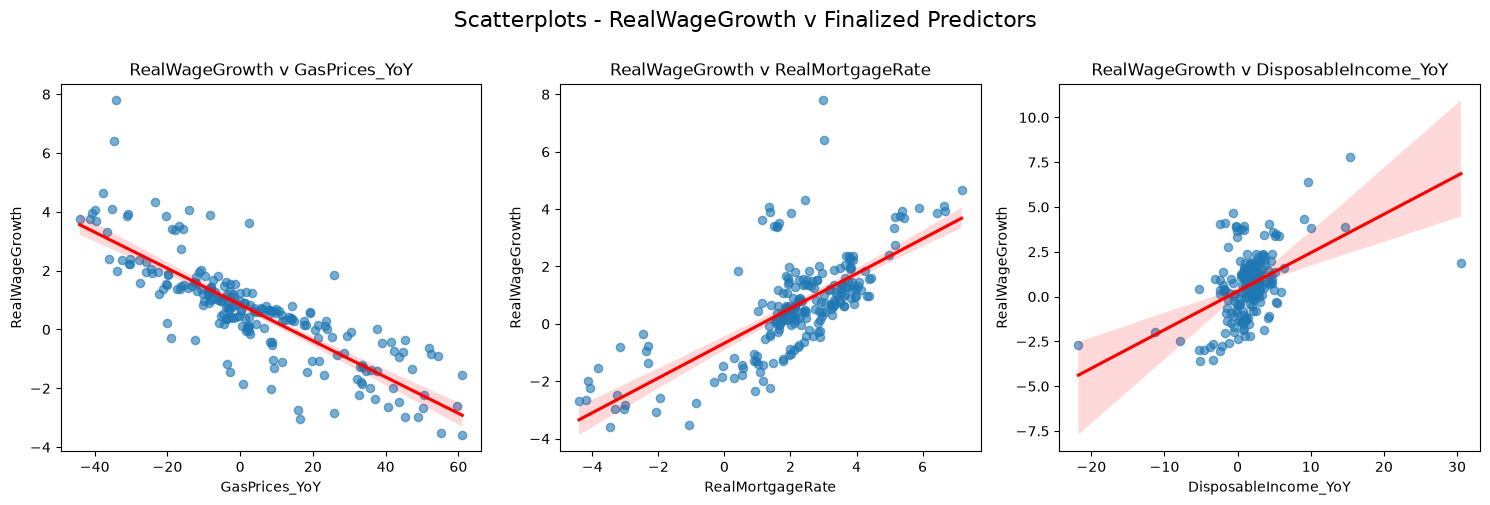

In [17]:
final_predictors = ["GasPrices_YoY",
                    "RealMortgageRate",
                    "DisposableIncome_YoY"]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes = axes.flatten()

for i, col in enumerate(final_predictors):
    sns.regplot(data=model_data,
                x=col,
                y=TARGET,
                scatter_kws={"alpha":0.6, "s":35},
                line_kws={"color":"red"},
                ax=axes[i])
    axes[i].set_title(f"{TARGET} v {col}")

fig.suptitle(f"Scatterplots - {TARGET} v Finalized Predictors",
             x=0.5,
             y=1,
             ha="center",
             fontsize=16)
plt.tight_layout()
plt.show()

# DisposableIncome_YoY: High-Leverage Month Review

In [18]:
top_dpi = model_data.reindex(
    model_data["DisposableIncome_YoY"].abs().sort_values(ascending=False).index
)[["Date", "DisposableIncome_YoY", TARGET]].head(5)

print(top_dpi)

          Date  DisposableIncome_YoY  RealWageGrowth
158 2021-03-01                 30.52            1.85
170 2022-03-01                -21.76           -2.68
147 2020-04-01                 15.40            7.79
156 2021-01-01                 14.63            3.91
168 2022-01-01                -11.27           -1.98


# DisposableIncome_YoY Stimulus Month Check

In [19]:
stimulus_months = pd.to_datetime(["2020-04-01", "2021-01-01", "2021-03-01", "2022-01-01", "2022-03-01"])
stimulus_mask = model_data["Date"].isin(stimulus_months)

corr_with = model_data[TARGET].corr(model_data["DisposableIncome_YoY"])
corr_without = model_data.loc[~stimulus_mask, TARGET].corr(model_data.loc[~stimulus_mask, "DisposableIncome_YoY"])

print(f"With stimulus months: {corr_with:.3f}")
print(f"Without stimulus months: {corr_without:.3f}")

With stimulus months: 0.472
Without stimulus months: 0.461


**Close out EDA**

The `leverage_notes` below were filled in after the modeling stage (`03_modeling.ipynb`), not during EDA. They label months that later showed up as influential (high Cook's distance) or as large misses, so the modeling notebook can display them alongside its diagnostics. The Cook's D values in parentheses come from the models in `03_modeling.ipynb`. "Regime 4" refers to a fourth period added after the three crisis windows defined above (the 2008 Recession, COVID, and the 2026 Energy Shock): the October 2022 to July 2023 disinflation window, which becomes the `DisinflationPeriod` dummy in the modeling notebook.

In [20]:
final_columns = ["Date", TARGET, "GasPrices_YoY", "RealMortgageRate", "DisposableIncome_YoY",
                 "RealWageGrowth_Lag1"] # kept for separate modeling comparison

# New lagged variable adds 1 additional NaN
model_data_final = model_data[final_columns].dropna().reset_index(drop=True)

# Flag months identifiable as high leverage
leverage_notes = {
    "2008-11-01": "High Cook's D / high residual",
    "2009-11-01": "High Cook's D (0.039)",
    "2009-12-01": "GasPrices base-effect",
    "2010-01-01": "GasPrices base-effect",
    "2020-04-01": "COVID stimulus/outlier",
    "2020-12-01": "High Cook's D (0.036)",
    "2021-01-01": "Stimulus",
    "2021-02-01": "High Cook's D, driver unclear",
    "2021-03-01": "Stimulus",
    "2021-04-01": "AR residual echo, highest Cook's D in final model (0.875)",
    "2021-06-01": "High Cook's D (0.028)",
    "2021-10-01": "High Cook's D (0.040)",
    "2021-11-01": "High Cook's D (0.037)",
    "2022-01-01": "DPI base-effect",
    "2022-03-01": "Gas price shock",
    "2022-07-01": "GasPrices base-effect",
    "2022-09-01": "High Cook's D (0.050)",
    "2022-10-01": "Disinflation/rate-hike (candidate Regime 4)",
    "2022-11-01": "Disinflation/rate-hike (candidate Regime 4)",
    "2022-12-01": "Disinflation/rate-hike (candidate Regime 4)",
    "2023-01-01": "Disinflation/rate-hike (candidate Regime 4)",
    "2023-02-01": "Disinflation/rate-hike (candidate Regime 4)",
    "2023-03-01": "Disinflation/rate-hike (candidate Regime 4)",
    "2023-04-01": "Disinflation/rate-hike (candidate Regime 4)",
    "2023-05-01": "Disinflation/rate-hike (candidate Regime 4)",
    "2023-06-01": "Disinflation/rate-hike (candidate Regime 4)",
    "2023-07-01": "Disinflation/rate-hike (candidate Regime 4)"
}

model_data_final["LeverageNote"] = pd.to_datetime(model_data_final["Date"]).dt.strftime("%Y-%m-%d").map(leverage_notes)

print("Final modeling dataset shape:", model_data_final.shape)
print("Date range:", model_data_final["Date"].min(), "to", model_data_final["Date"].max())

model_data_final.to_csv("../data/processed/model_data_final.csv", index=False)

Final modeling dataset shape: (220, 7)
Date range: 2008-02-01 00:00:00 to 2026-05-01 00:00:00


EDA Summary:

**Target:**

*   RealWageGrowth (WageGrowth_YoY - Inflation)

**Finalized Predictor Set:**
*   GasPrices_YoY
*   RealMortgageRate
*   DisposableIncome_YoY (retained with caution)






